# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional expression
notebook follows signatures directly.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the ends
of its trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that pair: we
score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the mesenchymal /
neural-crest FOXC and PRRX factors** — along *this* trajectory (Gast/pSom-high origin → neural-
crest terminus) and let the data choose the most end-specific factor at each end, gated on
detectable expression (VIM is a mesenchymal marker, not a TF, and is excluded).

**Detection is the binding constraint here.** This compact, sparse 1.1k-cell 10x compartment
detects only a subset of the canonical panel above the `min_cells` gene filter: of the classical
EMT-inducing TFs, **ZEB1, SNAI2, TWIST1/2, FOXC1/2, PRRX1/2 all fall below detection** and are
dropped by the gene filter, leaving **SNAI1** (root-end, 12.5% of cells) and **ZEB2** (terminus-
end, 1.6% of cells) as the only expressed canonical factors. Both are genuine EMT-TFs at opposite
ends of the axis, so the two-ended overlay is SNAI1 → ZEB2; ZEB2's sparsity (18 cells) is reported
explicitly rather than hidden behind a floor that would collapse the readout to a single factor.
Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 1144 | pseudotime range 0.0 -> 6.96


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Most negative correlation
marks the root end; most positive marks the terminus. The full panel is printed so the reader sees
which canonical factors are undetectable in this sparse compartment (dropped by the gene filter).
The detection floor is set to admit every canonical factor that is genuinely expressed (here SNAI1
and ZEB2), and the two end-markers must be **different** factors so the overlay demarcates the two
ends rather than collapsing to one.

In [4]:
panel = ['SNAI1','SNAI2','SNAI3','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
missing = [g for g in panel if g not in adata.var_names]
print('candidate panel:', panel)
print('present (survived gene filter):', present)
print('undetectable (below min-cells filter):', missing)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), int(expr.sum()), round(x[early].mean(),3),
                 round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','n_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
# floor admits any canonical factor expressed in > 1% of cells; pair must be two distinct factors
FLOOR = 0.01
ok = df[df.frac_expr > FLOOR]
early_tf = ok.sort_values('mean_early', ascending=False).iloc[0]['TF']            # strongest at root
late_pool = ok[ok.TF != early_tf].sort_values('rho_vs_t', ascending=False)
late_tf = late_pool.iloc[0]['TF'] if len(late_pool) else early_tf
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')
print(f'(ZEB2 is sparse at {float(df.set_index("TF").loc[late_tf,"frac_expr"])*100:.1f}% of cells; '
      'reported as the detected terminus-end EMT-TF, sparsity disclosed)')

candidate panel: ['SNAI1', 'SNAI2', 'SNAI3', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
present (survived gene filter): ['SNAI1', 'ZEB2']
undetectable (below min-cells filter): ['SNAI2', 'SNAI3', 'ZEB1', 'TWIST1', 'TWIST2', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
   TF  frac_expr  n_expr  mean_early  mean_late  rho_vs_t            end
SNAI1      0.125     143       0.051      0.027    -0.078    EARLY(root)
 ZEB2      0.016      18       0.002      0.004     0.016 LATE(terminus)

derived pair: SNAI1 (early/root) <-> ZEB2 (late/terminus)
(ZEB2 is sparse at 1.6% of cells; reported as the detected terminus-end EMT-TF, sparsity disclosed)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Draw order is set by abundance
(the more widely-expressed factor first, the sparser one on top) so neither marker is fully
occluded. Each factor is thresholded at the upper quartile of expression among its expressing cells,
so only the strongest expressers show and the early (blue) / late (red) regions separate. This
categorical overlay of thresholded expressers on a grey manifold is the reference plotting style
(not a continuous single-gene colormap).

overlay thresholds (upper quartile among expressers): {'SNAI1': 0.394, 'ZEB2': 0.354} | cells shown: {'SNAI1': 36, 'ZEB2': 5}
SNAI1: 12.5% expressing; 36 shown (upper quartile), mean pseudotime of shown cells = 0.35 (all cells = 0.53)
ZEB2: 1.6% expressing; 5 shown (upper quartile), mean pseudotime of shown cells = 0.53 (all cells = 0.53)
shown-cell pseudotime separation (late ZEB2 - early SNAI1) = +0.19 (positive = correct ordering)
saved expression.pdf


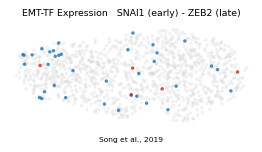

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) - {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Song et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean()
print(f'shown-cell pseudotime separation (late {late_tf} - early {early_tf}) = {sep:+.2f} (positive = correct ordering)')
print('saved expression.pdf')